In [2]:
import pandas as pd
df = pd.read_csv('MedQuAD_Dataset_RAG_Scenario.csv') # Load the MedQuAD dataset from a CSV file into a pandas DataFrame.

In [3]:
print(df.head()) # Display the first few rows of the DataFrame to get an overview of the data.

                                 question  \
0                What is (are) Glaucoma ?   
1                  What causes Glaucoma ?   
2     What are the symptoms of Glaucoma ?   
3  What are the treatments for Glaucoma ?   
4                What is (are) Glaucoma ?   

                                              answer           source  \
0  Glaucoma is a group of diseases that can damag...  NIHSeniorHealth   
1  Nearly 2.7 million people have glaucoma, a lea...  NIHSeniorHealth   
2  Symptoms of Glaucoma  Glaucoma can develop in ...  NIHSeniorHealth   
3  Although open-angle glaucoma cannot be cured, ...  NIHSeniorHealth   
4  Glaucoma is a group of diseases that can damag...  NIHSeniorHealth   

  focus_area  
0   Glaucoma  
1   Glaucoma  
2   Glaucoma  
3   Glaucoma  
4   Glaucoma  


In [4]:
print(df.info()) # Display information about the DataFrame, including the number of non-null entries and data types for each column.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16412 entries, 0 to 16411
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   question    16412 non-null  object
 1   answer      16407 non-null  object
 2   source      16412 non-null  object
 3   focus_area  16398 non-null  object
dtypes: object(4)
memory usage: 513.0+ KB
None


In [5]:
print(df[df['answer'].isnull()]) # Display rows where the 'answer' column is null to identify any missing answers in the dataset.

                                               question answer source  \
3591                     What is (are) HELLP syndrome ?    NaN   GARD   
3840  What is (are) X-linked lymphoproliferative syn...    NaN   GARD   
4200            What is (are) Familial HDL deficiency ?    NaN   GARD   
4433  What is (are) Emery-Dreifuss muscular dystroph...    NaN   GARD   
6693  What is (are) Emery-Dreifuss muscular dystroph...    NaN   GARD   

                                            focus_area  
3591                                    HELLP syndrome  
3840             X-linked lymphoproliferative syndrome  
4200                           Familial HDL deficiency  
4433       Emery-Dreifuss muscular dystrophy, X-linked  
6693  Emery-Dreifuss muscular dystrophy, dominant type  


In [6]:
print(df[df['focus_area'].isnull()]) # Display rows where the 'focus_area' column is null to identify any missing focus areas in the dataset.

                                               question  \
7885                                   What is (are)  ?   
7886          what is vancomycin-resistant enterococci?   
7887  what types of infections does vancomycin-resis...   
7888  are certain people at risk of getting vancomyc...   
7889  what is the treatment for vancomycin-resistant...   
7890  how can patients prevent the spread of vancomy...   
8077                                   What is (are)  ?   
8078                     what is staphylococcus aureus?   
8079  how can the spread of visa and vrsa be prevented?   
8080        what is cdc doing to address visa and vrsa?   
8081                       how vaccines prevent disease   
8082                             Who is at risk for ? ?   
8083                                  How to prevent  ?   
8084              what diseases are vaccine preventable   

                                                 answer source focus_area  
7885  On this Page General Information

In [7]:
df = df.dropna(subset=['answer']) # Drop rows with null values in the 'answer' column to clean the dataset.

In [8]:
print(df.info()) # Display information about the cleaned DataFrame to confirm that rows with null values have been removed.

<class 'pandas.core.frame.DataFrame'>
Index: 16407 entries, 0 to 16411
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   question    16407 non-null  object
 1   answer      16407 non-null  object
 2   source      16407 non-null  object
 3   focus_area  16393 non-null  object
dtypes: object(4)
memory usage: 640.9+ KB
None


In [9]:
print(df['focus_area'].value_counts()) # Display the count of unique values in the 'focus_area' column to understand the distribution of focus areas in the dataset.

focus_area
Breast Cancer                      53
Prostate Cancer                    43
Stroke                             35
Skin Cancer                        34
Alzheimer's Disease                30
                                   ..
Vision Impairment and Blindness     1
Nose Injuries and Disorders         1
Diphtheria                          1
Esophageal Cancer                   1
HIV/AIDS Medicines                  1
Name: count, Length: 5125, dtype: int64


In [10]:
print(df['focus_area'].value_counts()[df['focus_area'].value_counts() > 1]) # Display focus areas that have more than one record to identify common focus areas in the dataset.

focus_area
Breast Cancer                                 53
Prostate Cancer                               43
Stroke                                        35
Skin Cancer                                   34
Alzheimer's Disease                           30
                                              ..
Idiopathic acute eosinophilic pneumonia        2
Kidney Failure: What to Expect                 2
Myelodysplastic/myeloproliferative disease     2
BOD syndrome                                   2
Brittle cornea syndrome                        2
Name: count, Length: 2793, dtype: int64


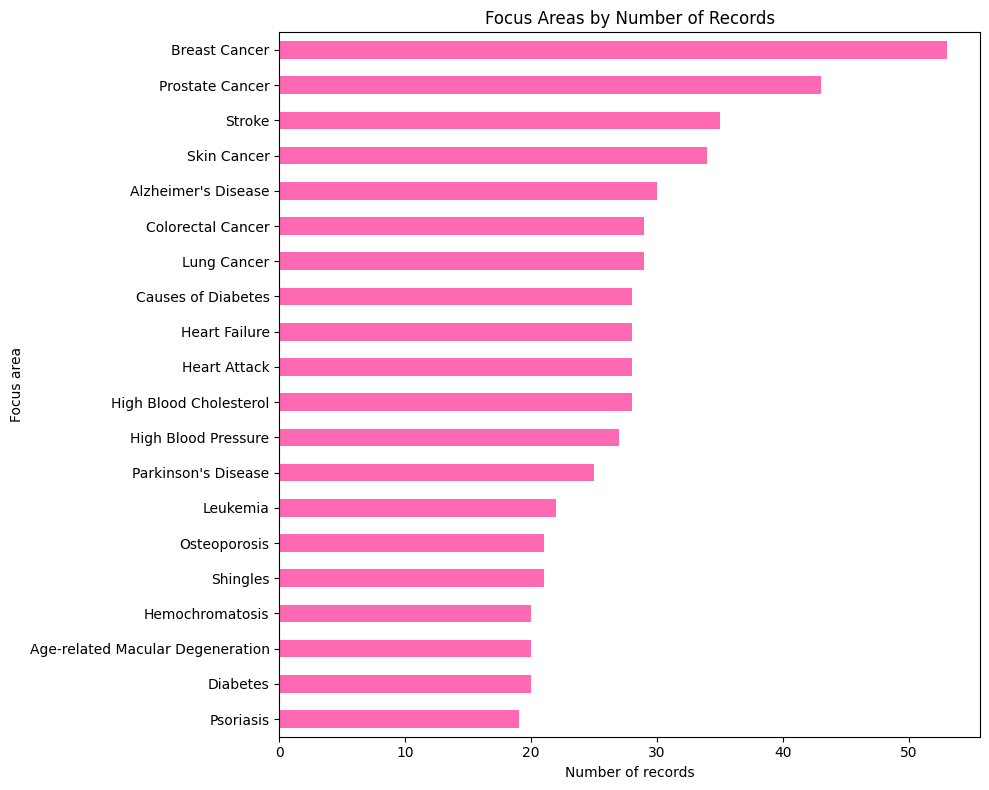

In [11]:
import matplotlib.pyplot as plt

focus_area_counts = df['focus_area'].value_counts().head(20).sort_values()

ax = focus_area_counts.plot(kind='barh', figsize=(10, 8), color='hotpink')
ax.set_title('Focus Areas by Number of Records')
ax.set_xlabel('Number of records')
ax.set_ylabel('Focus area')
plt.tight_layout()
plt.show() # Display a horizontal bar chart of the top 20 focus areas by number of records to visualize the distribution of focus areas in the dataset.

In [12]:
print(df['source'].value_counts()) # Display the count of unique values in the 'source' column to understand the distribution of sources in the dataset.

source
GHR                  5430
GARD                 5389
NIDDK                1192
NINDS                1088
MPlusHealthTopics     981
NIHSeniorHealth       769
CancerGov             729
NHLBI                 559
CDC                   270
Name: count, dtype: int64


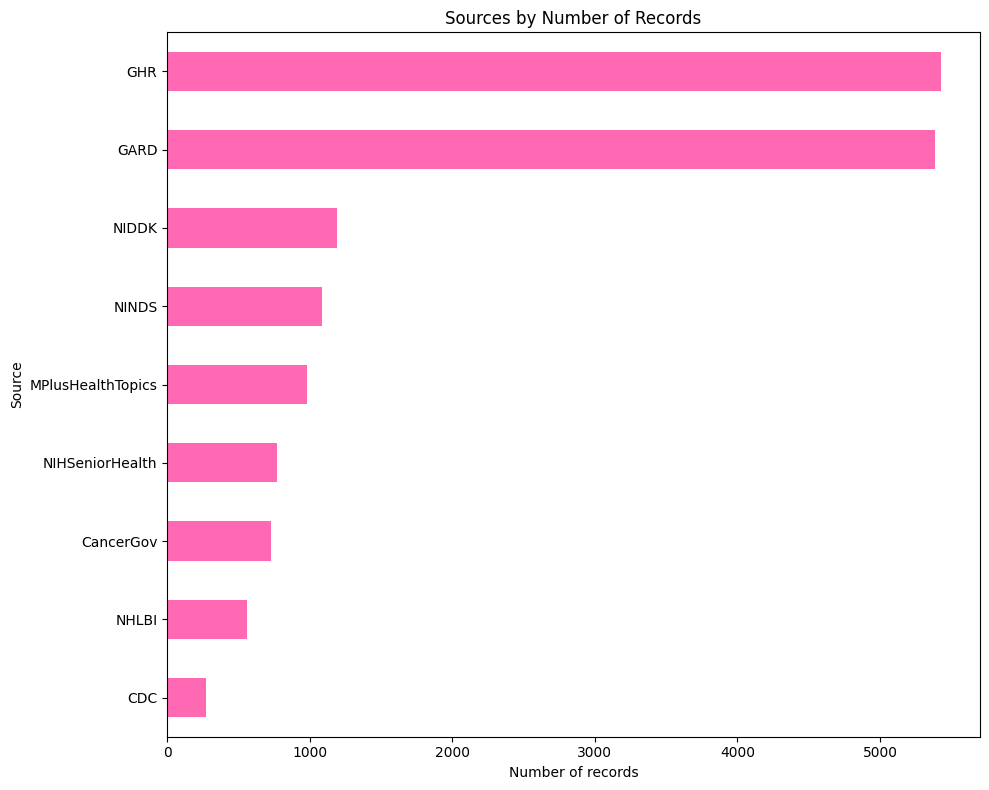

In [13]:
focus_area_counts = df['source'].value_counts().sort_values()

ax = focus_area_counts.plot(kind='barh', figsize=(10, 8), color='hotpink')
ax.set_title('Sources by Number of Records')
ax.set_xlabel('Number of records')
ax.set_ylabel('Source')
plt.tight_layout()
plt.show() # Display a horizontal bar chart of the sources by number of records to visualize the distribution of sources in the dataset.

In [14]:
print(max(df['question'].str.len())) # Display descriptive statistics for the 'question' column to understand the distribution of question lengths in the dataset.

191


In [15]:
print(max(df['answer'].str.len())) # Display descriptive statistics for the 'answer' column to understand the distribution of answer lengths in the dataset.

29046


In [16]:
print(df['answer'].str.len().describe()) # Display descriptive statistics for the 'answer' column to understand the distribution of answer lengths in the dataset.

count    16407.000000
mean      1301.189492
std       1657.651513
min          6.000000
25%        484.000000
50%        888.000000
75%       1587.000000
max      29046.000000
Name: answer, dtype: float64


In [17]:
print(df['answer'].str.len().quantile(0.99)) # Display the 99th percentile of answer lengths to understand the upper range of answer lengths in the dataset.

8364.680000000011


In [18]:
print(df['answer'].str.len().quantile(0.95)) # Display the 95th percentile of answer lengths to understand the upper range of answer lengths in the dataset.

3399.399999999998


In [19]:
max_idx = df['answer'].str.len().idxmax() # Find the index of the row with the longest answer in the dataset.
print(df.loc[[max_idx]].to_string(index=False, max_colwidth=None)) # Display the row with the longest answer in the dataset to examine its content and context.

                                   question                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                             

In [20]:
from sentence_transformers import SentenceTransformer
model = SentenceTransformer('Qwen/Qwen3-Embedding-0.6B') # Load the Qwen3-Embedding model from the Sentence Transformers library to generate embeddings for the questions in the dataset.
questions = df['question'].tolist() # Convert the 'question' column of the DataFrame to a list of questions for embedding generation.
question_embeddings = model.encode(questions, normalize_embeddings=True) # Generate embeddings for the questions in the dataset.

print("Embedding shape:", question_embeddings.shape) # Display the shape of the generated question embeddings to understand the dimensionality of the embeddings.
print("First 5 values:", question_embeddings[0][:5]) # Display the first 5 values of the first question embedding to examine the content of the embeddings.

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

This model was loaded in torch.bfloat16 on CPU. Depending on your CPU, inference may be significantly slower than with torch.float32. Consider comparing inference speeds by loading with `model_kwargs={"dtype": torch.float32}`.


Embedding shape: (16407, 1024)
First 5 values: [-0.03637695 -0.06689453 -0.01300049  0.00157928  0.03979492]


In [21]:
import numpy as np
np.save('question_embeddings.npy', question_embeddings) # Save the generated question embeddings to a NumPy file for later use in retrieval tasks.

In [22]:
import faiss
index = faiss.IndexFlatIP(question_embeddings.shape[1])
index.add(question_embeddings)

print("Number of indexed questions:", index.ntotal)

Number of indexed questions: 16407


In [26]:
def retrieve(question, k=3):
    q_emb = model.encode(
        [question],
        normalize_embeddings=True
    )

    scores, indices = index.search(q_emb, k)

    results = []

    for idx, score in zip(indices[0], scores[0]):
        row = df.iloc[idx]
        results.append({
            "question": row["question"],
            "answer": row["answer"],
            "score": float(score)
        })

    return results

In [28]:
retrieve("how to define glaucoma please?", k=3)

[{'question': 'What is (are) Glaucoma ?',
  'answer': 'The optic nerve is a bundle of more than 1 million nerve fibers. It connects the retina to the brain.',
  'score': 0.863227128982544},
 {'question': 'What is (are) Glaucoma ?',
  'answer': "Glaucoma is a group of diseases that can damage the eye's optic nerve and result in vision loss and blindness. The most common form of the disease is open-angle glaucoma. With early treatment, you can often protect your eyes against serious vision loss. (Watch the video to learn more about glaucoma. To enlarge the video, click the brackets in the lower right-hand corner. To reduce the video, press the Escape (Esc) button on your keyboard.)  See this graphic for a quick overview of glaucoma, including how many people it affects, whos at risk, what to do if you have it, and how to learn more.  See a glossary of glaucoma terms.",
  'score': 0.863227128982544},
 {'question': 'What is (are) Glaucoma ?',
  'answer': "Glaucoma is a group of diseases th

In [29]:
print(df['question'].nunique) # Display the number of unique questions in the dataset to understand the diversity of questions present.

<bound method IndexOpsMixin.nunique of 0                                 What is (are) Glaucoma ?
1                                   What causes Glaucoma ?
2                      What are the symptoms of Glaucoma ?
3                   What are the treatments for Glaucoma ?
4                                 What is (are) Glaucoma ?
                               ...                        
16407    What is (are) Diabetic Neuropathies: The Nerve...
16408    How to prevent Diabetic Neuropathies: The Nerv...
16409    How to diagnose Diabetic Neuropathies: The Ner...
16410    What are the treatments for Diabetic Neuropath...
16411    What to do for Diabetic Neuropathies: The Nerv...
Name: question, Length: 16407, dtype: object>
